# PROJECT ODIN
## From Churn Risk to Profitable Customer Retention Decisions

**Project type:** Data Analytics / Machine Learning-informed Business Decision Optimization  
**Business domain:** Subscription-based businesses  
**Primary question:** With a limited retention campaign budget, which customers should receive retention offers to maximize expected net financial benefit?

---

## How to read this notebook

This notebook tells a business and analytical story. Each section answers a question:

1. **Why does this business problem matter?** Understand the decision the company needs to make.
2. **What information do we have?** Understand the dataset, each field, and its limitations.
3. **Can we trust the data enough to analyze it?** Inspect and validate the supplied records.
4. **How do we translate customer risk into financial value?** Define the assumptions and formulas.
5. **How should we allocate a limited budget?** Compare three decision strategies.
6. **How do we know which strategy performs better?** Evaluate financial and retrospective metrics.
7. **Would the recommendation change under different assumptions?** Run sensitivity analysis.
8. **What should the business do?** Interpret the evidence and state a careful recommendation.
9. **Is the answer verifiably optimal, and how risky is it?** Verification, a stronger heuristic, Monte Carlo risk and a two-way scenario map.

**Important:** This is not a notebook that trains a churn prediction model. It uses a prepared synthetic dataset containing simulated churn probabilities. The project focuses on the decision and optimization layer that can use churn predictions as inputs.

### Project files

This notebook lives in `notebooks/` of the Project Odin repository. It reads the input from `data/raw/project_odin_customers.csv` and writes its charts and tables to `outputs/notebook/`.

The same logic is also packaged as a tested Python library in `src/odin/` (see section 17 and the repository README), which you can run from the command line with `python -m odin analyze`.


# 1. Business context: Why is this problem worth solving?

Imagine a subscription business with a customer base that changes over time. Some customers renew, while others cancel. Losing a customer can mean losing future revenue and the economic value that customer could have generated.

A business may try to reduce cancellations through retention campaigns. However, each intervention has a cost: a discount, free month, service upgrade, or another incentive. The campaign budget is limited, so the business cannot necessarily contact every customer.

A common first instinct is to target customers with the highest probability of churn. That sounds reasonable, but it can be financially inefficient:

- A high-risk customer may have a relatively low lifetime value.
- A valuable customer may have a moderate churn probability but a much higher potential value to preserve.
- Two customers may have similar risk but very different offer costs.
- Choosing customers one by one by risk does not necessarily produce the best combination under a fixed budget.

## The decision problem

The business is not simply asking:

> Who is most likely to leave?

It is asking:

> Which combination of customers should receive retention offers so that the total expected financial benefit is as high as possible, without spending more than the available budget?

This is a **budget-constrained decision optimization problem**.

## Why combine analytics and optimization?

The analysis has two connected layers:

1. **Customer-level economic estimation:** translate risk, customer value, and offer cost into an estimated net benefit for each customer.
2. **Portfolio-level budget allocation:** choose the combination of customers that produces the highest total expected net benefit under the campaign budget.

The distinction matters. A customer can look attractive individually, but the best set of customers is the combination that creates the greatest total value while respecting the budget.

# 2. Project objective, scope, and decision criteria

## Objective

Identify a set of customers for a retention campaign that maximizes total expected net financial benefit under a fixed campaign budget.

## Scope

This project:
- analyzes 30 fictional customer records;
- uses supplied churn probabilities, rather than training a predictive model;
- uses estimated customer lifetime value and retention-offer cost;
- assumes a hypothetical retention-offer success rate;
- compares random selection, highest-churn-probability selection, and 0/1 Knapsack optimization;
- evaluates financial outcomes and retrospective actual-churn capture;
- tests how the result changes under alternative success-rate and budget assumptions.

## What this project does not claim

It does not prove that a real retention campaign will cause the estimated savings. It does not establish that the simulated churn probabilities are calibrated or accurate. It does not estimate a causal treatment effect. Those would require real historical data, a validated predictive model, and ideally experimental evidence about intervention effectiveness.

## Main decision criteria

The primary decision metric is **total expected net benefit**. We also monitor campaign spending, number of customers selected, expected retained value, and actual churn capture rate as a retrospective descriptive measure.

# 3. Understand the dataset before calculating anything

The supplied file is `project_odin_customers.csv`. It contains one row per fictional customer and five input fields.

| Field | Meaning | Why it matters |
|---|---|---|
| `Customer_ID` | Unique customer identifier | Allows us to track selected customers |
| `Actual_Churn` | Historical outcome: 1 = churned, 0 = did not churn | Used only for retrospective evaluation |
| `Predicted_Churn_Probability` | Simulated probability of churn | Represents the risk signal available to the decision process |
| `Estimated_CLV` | Estimated customer lifetime value, in euros | Represents the economic value potentially preserved |
| `Retention_Offer_Cost` | Estimated cost of the offer, in euros | Represents the campaign budget consumed by selecting the customer |

## What does one row represent?

One row represents one customer and the information available for the retention decision.

## Important distinction: actual churn vs. predicted churn probability

These fields are not interchangeable:

- `Actual_Churn` is a binary outcome: what happened in the simulated dataset.
- `Predicted_Churn_Probability` is a probability-like input: how likely the customer is estimated to churn.

In a real predictive workflow, the probability would be produced by a trained and validated churn model. In this project, it is simulated so that we can focus on how a business could use risk scores in a budget allocation decision.

## Why is the dataset synthetic?

The project brief defines a self-created synthetic dataset. This makes it possible to demonstrate the methodology without exposing real customer information. It also means the numerical results are illustrative and should not be presented as measured company performance.

# 4. Load the prepared dataset

We now load the existing CSV. We do not create or simulate customers in this notebook. The data file is the fixed input to the analysis.

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the repository root whether the notebook is run from notebooks/ or the root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
DATA_FILE = ROOT / "data" / "raw" / "project_odin_customers.csv"
OUTPUT_DIR = ROOT / "outputs" / "notebook"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Scenario assumptions: centralized for transparency and reproducibility
BASE_SUCCESS_RATE = 0.50
CAMPAIGN_BUDGET = 500
RANDOM_SEED = 42
SUCCESS_RATE_SCENARIOS = [0.30, 0.50, 0.70]
BUDGET_SCENARIOS = [350, 500, 650]

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "savefig.dpi": 200,
    "figure.dpi": 120
})

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_FILE}. Run the notebook from inside the repository."
    )

df = pd.read_csv(DATA_FILE)

print("Prepared dataset loaded.")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
display(df.head(10))

Prepared dataset loaded.
Number of rows: 30
Number of columns: 5


,Customer_ID,Actual_Churn,Predicted_Churn_Probability,Estimated_CLV,Retention_Offer_Cost
0,C001,1,0.72,1669,92
1,C002,0,0.45,1366,137
2,C003,1,0.79,723,141
3,C004,0,0.66,1745,86
4,C005,0,0.18,798,148
5,C006,1,0.88,654,74
6,C007,1,0.71,1640,68
7,C008,1,0.73,730,122
8,C009,0,0.20,229,117
9,C010,0,0.46,898,56


**How to explain this step:** “I start from a prepared customer-level dataset. Each row represents one customer. I load the CSV as the source data for the analysis; I do not generate customer records inside the analytical notebook.”

The first preview is not yet an analysis result. It is a quick check that the file loaded and that the records look as expected.

# 5. Data quality assessment: Can we use these records?

Before calculating business metrics, an analyst checks whether the data is structurally sound. If customer IDs are duplicated, values are missing, probabilities fall outside the valid range, or costs are invalid, the later calculations may be misleading.

We will check:
- required columns;
- data types;
- missing values;
- duplicate customer IDs;
- binary churn labels;
- churn probabilities between 0 and 1;
- positive CLV and offer costs.

In [2]:
EXPECTED_COLUMNS = [
    "Customer_ID",
    "Actual_Churn",
    "Predicted_Churn_Probability",
    "Estimated_CLV",
    "Retention_Offer_Cost"
]

missing_columns = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df = df[EXPECTED_COLUMNS].copy()
df["Customer_ID"] = df["Customer_ID"].astype(str)
df["Actual_Churn"] = pd.to_numeric(df["Actual_Churn"], errors="raise").astype(int)

numeric_columns = [
    "Predicted_Churn_Probability",
    "Estimated_CLV",
    "Retention_Offer_Cost"
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="raise")

print("Data types:")
display(df.dtypes.to_frame("Data type"))

print("Missing values by column:")
display(df.isna().sum().to_frame("Missing values"))

checks = {
    "All required columns are present": len(missing_columns) == 0,
    "Customer IDs are unique": df["Customer_ID"].is_unique,
    "No missing values": not df.isna().any().any(),
    "Actual churn contains only 0 and 1": df["Actual_Churn"].isin([0, 1]).all(),
    "Churn probabilities are between 0 and 1":
        df["Predicted_Churn_Probability"].between(0, 1).all(),
    "CLV values are positive": (df["Estimated_CLV"] > 0).all(),
    "Offer costs are positive": (df["Retention_Offer_Cost"] > 0).all(),
    "Offer costs are whole euros":
        np.allclose(df["Retention_Offer_Cost"] % 1, 0)
}

print("Validation results:")
for label, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} — {label}")

if not all(checks.values()):
    raise ValueError("Data validation failed. Resolve the issues before proceeding.")

print("\nDataset validation completed successfully.")

Data types:


,Data type
Customer_ID,object
Actual_Churn,int64
Predicted_Churn_Probability,float64
Estimated_CLV,int64
Retention_Offer_Cost,int64


Missing values by column:


,Missing values
Customer_ID,0
Actual_Churn,0
Predicted_Churn_Probability,0
Estimated_CLV,0
Retention_Offer_Cost,0


Validation results:
PASS — All required columns are present
PASS — Customer IDs are unique
PASS — No missing values
PASS — Actual churn contains only 0 and 1
PASS — Churn probabilities are between 0 and 1
PASS — CLV values are positive
PASS — Offer costs are positive
PASS — Offer costs are whole euros

Dataset validation completed successfully.


## How to interpret the quality checks

A “PASS” does not mean the dataset is realistic or representative of a real company. It means the records satisfy the structural rules we defined for this analysis.

For this dataset, the expected outcome is 30 rows, five fields, unique customer IDs, no missing values, binary actual churn labels, valid probabilities, and positive financial values.

An analyst must separate **technical validity** (the file is structured correctly) from **business validity** (the values represent reality). Our synthetic data can pass technical checks without being real-world evidence.

# 6. Exploratory data analysis: What does the customer base look like?

Before optimizing the campaign, we should understand the range and distribution of the input variables.

We examine:
- the number of actual churners and non-churners;
- the distribution of supplied churn probabilities;
- the range of estimated customer values;
- the range of retention offer costs.

This step helps us understand the data we are about to use. It does not prove predictive model accuracy.

Customers in dataset: 30
Actual churners: 15
Actual non-churners: 15


,count,mean,std,min,25%,50%,75%,max
Predicted_Churn_Probability,30.0,0.55,0.24,0.14,0.38,0.62,0.73,0.88
Estimated_CLV,30.0,995.50,469.35,229.00,655.75,903.50,1396.00,1745.00
Retention_Offer_Cost,30.0,100.30,33.66,40.00,70.00,104.00,134.00,148.00


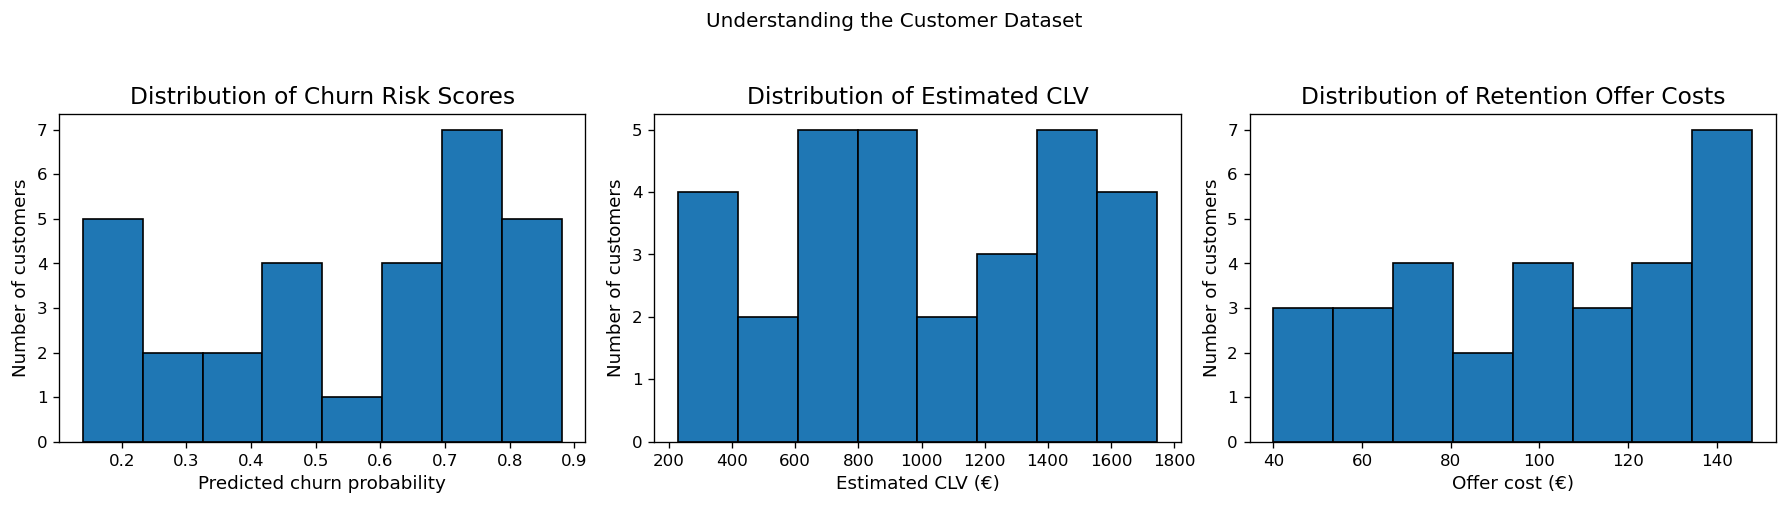

In [3]:
print(f"Customers in dataset: {len(df)}")
print(f"Actual churners: {(df['Actual_Churn'] == 1).sum()}")
print(f"Actual non-churners: {(df['Actual_Churn'] == 0).sum()}")

display(
    df[[
        "Predicted_Churn_Probability",
        "Estimated_CLV",
        "Retention_Offer_Cost"
    ]].describe().T.round(2)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df["Predicted_Churn_Probability"], bins=8, edgecolor="black")
axes[0].set_title("Distribution of Churn Risk Scores")
axes[0].set_xlabel("Predicted churn probability")
axes[0].set_ylabel("Number of customers")

axes[1].hist(df["Estimated_CLV"], bins=8, edgecolor="black")
axes[1].set_title("Distribution of Estimated CLV")
axes[1].set_xlabel("Estimated CLV (€)")
axes[1].set_ylabel("Number of customers")

axes[2].hist(df["Retention_Offer_Cost"], bins=8, edgecolor="black")
axes[2].set_title("Distribution of Retention Offer Costs")
axes[2].set_xlabel("Offer cost (€)")
axes[2].set_ylabel("Number of customers")

fig.suptitle("Understanding the Customer Dataset", y=1.04)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_customer_dataset_overview.png", bbox_inches="tight")
plt.show()
plt.close(fig)

## What should an analyst look for here?

- **Churn probability:** Are the supplied risk scores spread across low, medium, and high values, or concentrated in one narrow range?
- **CLV:** Are customer values similar, or do some customers have substantially higher estimated value?
- **Offer cost:** Are retention offers similarly priced, or do costs vary materially by customer?

The business reason for examining all three is that the decision depends on their combination. Looking at churn probability alone would ignore customer value and intervention cost.

# 7. Define the business assumptions and financial logic

We need a way to estimate whether offering a retention incentive to a customer makes economic sense.

The project uses two scenario assumptions:

| Assumption | Base value | Why it is needed |
|---|---:|---|
| Retention success rate | 50% | Represents the assumed chance that the offer prevents churn for a customer who would otherwise leave |
| Campaign budget | €500 | Represents the maximum total spend available for the campaign |

These values are **hypothetical scenario inputs**, not values learned from the dataset and not measured campaign results. They are chosen to demonstrate the decision framework. In a real company, they should be informed by experiments, historical campaign results, finance, and campaign constraints.

## Formula 1 — Expected retained value

\[
ERV_i = P_i(\text{churn}) \times CLV_i \times r
\]

Where:
- \(ERV_i\): expected retained value for customer \(i\)
- \(P_i(\text{churn})\): supplied probability that customer \(i\) will churn
- \(CLV_i\): estimated lifetime value of customer \(i\)
- \(r\): assumed retention-offer success rate

**Plain-language interpretation:** We estimate the value at risk from a possible cancellation, then multiply it by the assumed chance that the retention offer successfully prevents that cancellation.

For example, if a customer has a 0.60 churn probability, an estimated CLV of €1,000, and the assumed offer success rate is 50%, then:

\[
ERV = 0.60 \times 1000 \times 0.50 = €300
\]

This €300 is a scenario-based expected value, not a guaranteed saving.

## Formula 2 — Expected net benefit

\[
ENB_i = ERV_i - C_i
\]

Where:
- \(ENB_i\): expected net benefit for customer \(i\)
- \(C_i\): cost of the retention offer

**Plain-language interpretation:** After estimating the value the offer may preserve, subtract what the offer costs.

Using the example above, if the offer costs €80:

\[
ENB = €300 - €80 = €220
\]

Under these assumptions, the offer has a positive expected net benefit of €220.

If the result is negative, the estimated retained value is lower than the offer cost. That customer would not be an attractive choice under this simple financial model.

## Important modeling assumption

This calculation treats the product of churn probability, CLV, and offer success rate as an estimate of value preserved by the offer. It assumes the success rate applies to the at-risk customer and that the relevant CLV can be treated as the value preserved. A real deployment would need a more precise definition of incremental value, intervention eligibility, timing, margins, and causal offer effectiveness.

# 8. Calculate expected value for every customer

Now that the business logic is clear, we apply the formulas to each row.

We keep the original input columns and add two calculated columns:
- `Expected_Retained_Value`
- `Expected_Net_Benefit`

This is the point where the dataset becomes a customer-level economic decision table.

In [4]:
BASE_SUCCESS_RATE = 0.50
CAMPAIGN_BUDGET = 500

df["Expected_Retained_Value"] = (
    df["Predicted_Churn_Probability"]
    * df["Estimated_CLV"]
    * BASE_SUCCESS_RATE
)

df["Expected_Net_Benefit"] = (
    df["Expected_Retained_Value"]
    - df["Retention_Offer_Cost"]
)

economic_columns = [
    "Customer_ID",
    "Predicted_Churn_Probability",
    "Estimated_CLV",
    "Retention_Offer_Cost",
    "Expected_Retained_Value",
    "Expected_Net_Benefit"
]
customer_economics = df[economic_columns].copy()

display(customer_economics.round(2))

print("Customer-level expected net benefit groups:")
print(f"Positive: {(df['Expected_Net_Benefit'] > 0).sum()}")
print(f"Zero: {(df['Expected_Net_Benefit'] == 0).sum()}")
print(f"Negative: {(df['Expected_Net_Benefit'] < 0).sum()}")

,Customer_ID,Predicted_Churn_Probability,Estimated_CLV,Retention_Offer_Cost,Expected_Retained_Value,Expected_Net_Benefit
0,C001,0.72,1669,92,600.84,508.84
1,C002,0.45,1366,137,307.35,170.35
2,C003,0.79,723,141,285.59,144.59
3,C004,0.66,1745,86,575.85,489.85
4,C005,0.18,798,148,71.82,-76.18
5,C006,0.88,654,74,287.76,213.76
6,C007,0.71,1640,68,582.20,514.20
7,C008,0.73,730,122,266.45,144.45
8,C009,0.20,229,117,22.90,-94.10
9,C010,0.46,898,56,206.54,150.54


Customer-level expected net benefit groups:
Positive: 25
Zero: 0
Negative: 5


## How to read the customer economics table

Each row now has an estimated financial result for the retention offer.

- A **positive** expected net benefit means estimated retained value is greater than offer cost.
- A **negative** expected net benefit means offer cost is greater than estimated retained value.
- The largest churn probability is not automatically the largest expected net benefit. CLV and offer cost also affect the result.

This table creates the economic basis for comparing customer selection strategies.

# 9. Establish comparison strategies

To judge whether optimization adds value, we need comparison approaches. We use three strategies.

### Strategy A — Random selection (baseline)

Customers are placed in a reproducibly shuffled order. We select a customer if the offer cost fits within the remaining budget. This gives us a simple baseline that does not prioritize churn risk or economic value.

### Strategy B — Highest churn probability

Customers are sorted from highest to lowest churn probability. We select them in that order whenever their offer cost fits within the remaining budget.

This represents a risk-first approach. It is intuitive, but it does not directly optimize financial benefit.

### Strategy C — 0/1 Knapsack optimization

We select the combination of customers that maximizes the sum of expected net benefits while keeping total offer cost within the budget.

This is the optimization-based approach and directly matches the project's objective.

**Fair comparison note:** The random and highest-churn strategies are simple sequential greedy rules. They are not guaranteed to be globally optimal. In this implementation they may select a customer with a negative expected net benefit, because their selection rules are based on random order or churn risk, not positive net benefit. This is useful to expose the difference between a risk-first rule and an economic optimization rule.

In [5]:
def random_selection(data, budget, seed=42):
    shuffled = data.sample(frac=1, random_state=seed)
    selected_ids = []
    spent = 0

    for _, customer in shuffled.iterrows():
        cost = int(customer["Retention_Offer_Cost"])
        if spent + cost <= budget:
            selected_ids.append(customer["Customer_ID"])
            spent += cost

    return selected_ids


def churn_based_selection(data, budget):
    ranked = data.sort_values(
        "Predicted_Churn_Probability",
        ascending=False,
        kind="mergesort"
    )
    selected_ids = []
    spent = 0

    for _, customer in ranked.iterrows():
        cost = int(customer["Retention_Offer_Cost"])
        if spent + cost <= budget:
            selected_ids.append(customer["Customer_ID"])
            spent += cost

    return selected_ids


def knapsack_selection(data, budget):
    if budget < 0 or int(budget) != budget:
        raise ValueError("Budget must be a non-negative whole number.")

    eligible = (
        data.loc[data["Expected_Net_Benefit"] > 0]
        .sort_values("Customer_ID")
        .reset_index(drop=True)
    )

    costs = eligible["Retention_Offer_Cost"].astype(int).tolist()
    benefits = eligible["Expected_Net_Benefit"].astype(float).tolist()
    customer_ids = eligible["Customer_ID"].tolist()

    n = len(eligible)
    capacity = int(budget)

    # Dynamic programming table:
    # dp[i][b] = best net benefit using first i customers with budget b.
    dp = [[0.0] * (capacity + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        cost = costs[i - 1]
        benefit = benefits[i - 1]

        for b in range(capacity + 1):
            dp[i][b] = dp[i - 1][b]
            if cost <= b:
                dp[i][b] = max(
                    dp[i][b],
                    benefit + dp[i - 1][b - cost]
                )

    # Backtrack to identify the selected customer combination.
    selected_ids = []
    remaining = capacity

    for i in range(n, 0, -1):
        if not math.isclose(
            dp[i][remaining],
            dp[i - 1][remaining],
            rel_tol=1e-12,
            abs_tol=1e-9
        ):
            selected_ids.append(customer_ids[i - 1])
            remaining -= costs[i - 1]

    return selected_ids[::-1]


strategies = {
    "Random": random_selection(df, CAMPAIGN_BUDGET, seed=42),
    "Highest Churn Probability":
        churn_based_selection(df, CAMPAIGN_BUDGET),
    "Knapsack Optimization":
        knapsack_selection(df, CAMPAIGN_BUDGET)
}

for strategy, customer_ids in strategies.items():
    print(f"{strategy}: {customer_ids}")

Random: ['C028', 'C016', 'C024', 'C018', 'C010']
Highest Churn Probability: ['C006', 'C023', 'C012', 'C024', 'C003']
Knapsack Optimization: ['C001', 'C004', 'C007', 'C021', 'C024', 'C030']


# 10. Understand the optimization: the 0/1 Knapsack Problem

The Knapsack Problem is a classic resource-allocation problem.

Imagine a bag that can carry no more than a fixed weight. Each item has:
- a weight;
- a value.

The objective is to choose the combination of items with the highest total value without exceeding the bag's capacity.

In our business problem:
- the “bag capacity” is the €500 campaign budget;
- each “item” is a customer retention offer;
- the “weight” is the offer cost;
- the “value” is the customer's expected net benefit.

## Mathematical formulation

Let \(x_i\) be a binary decision:
- \(x_i=1\): select customer \(i\);
- \(x_i=0\): do not select customer \(i\).

### Objective function

\[
\max \sum_{i=1}^{n} x_i ENB_i
\]

We want to maximize the sum of expected net benefits.

### Budget constraint

\[
\sum_{i=1}^{n} x_i C_i \leq B
\]

The total offer cost cannot exceed the campaign budget.

### Binary constraint

\[
x_i \in \{0,1\}
\]

A customer is either selected or not selected. We cannot select half a customer.

## Why dynamic programming?

Trying every possible customer combination becomes expensive as the number of customers grows. Dynamic programming solves the problem by building up the best achievable value for smaller groups of customers and smaller budget amounts, then using those results to solve larger subproblems.

For this small dataset, it is also possible to verify the result by enumerating combinations, but dynamic programming demonstrates a standard optimization method.

**Why exclude negative expected net benefit customers?** A negative-value offer reduces the objective and consumes budget. Since selecting nobody is allowed, an optimal solution to this objective never needs a negative-benefit customer.

# 11. Evaluate the three strategies

We now compare the strategies using the same set of metrics.

| Metric | Business interpretation |
|---|---|
| Selected Customers | How many customers receive an offer? |
| Total Spending | How much of the budget is used? |
| Expected Retained Value | Total modeled value expected to be preserved |
| Expected Net Benefit | Expected retained value minus offer costs |
| Actual Churners Captured | Number of selected customers whose actual churn label is 1 |
| Actual Churn Capture Rate | Share of all actual churners in the dataset who were selected |

The **primary metric** is expected net benefit because the project objective is financial optimization. Actual churn capture rate is a secondary retrospective metric. It is not the same as model recall and does not measure campaign causality.

In [6]:
def evaluate_strategy(data, selected_ids):
    selected = data[data["Customer_ID"].isin(selected_ids)].copy()

    spending = selected["Retention_Offer_Cost"].sum()
    retained_value = selected["Expected_Retained_Value"].sum()
    net_benefit = selected["Expected_Net_Benefit"].sum()

    churners_captured = int(selected["Actual_Churn"].sum())
    total_churners = int(data["Actual_Churn"].sum())

    capture_rate = (
        churners_captured / total_churners
        if total_churners > 0 else 0.0
    )

    return {
        "Selected Customers": len(selected),
        "Total Spending (€)": spending,
        "Expected Retained Value (€)": retained_value,
        "Expected Net Benefit (€)": net_benefit,
        "Actual Churners Captured": churners_captured,
        "Actual Churn Capture Rate": capture_rate
    }


comparison = pd.DataFrame({
    name: evaluate_strategy(df, ids)
    for name, ids in strategies.items()
}).T

display(comparison.round(2))

assert (comparison["Total Spending (€)"] <= CAMPAIGN_BUDGET).all()
print(f"Budget check passed: all strategies spend no more than €{CAMPAIGN_BUDGET}.")

,Selected Customers,Total Spending (€),Expected Retained Value (€),Expected Net Benefit (€),Actual Churners Captured,Actual Churn Capture Rate
Random,5.0,462.0,1028.32,566.32,1.0,0.07
Highest Churn Probability,5.0,481.0,1528.68,1047.68,5.0,0.33
Knapsack Optimization,6.0,467.0,3468.39,3001.39,5.0,0.33


Budget check passed: all strategies spend no more than €500.


## How to explain the comparison

Start with the primary metric: expected net benefit. Ask which strategy creates the highest modeled financial benefit while remaining within the budget.

Then look at the supporting metrics:
- Did the strategy spend the entire budget or leave some unused?
- How many customers did it select?
- Did selecting more customers necessarily create more value?
- How many actual churners were included?

Do not claim that a higher retrospective churn capture rate proves the retention offers worked. It only describes the actual churn labels among selected customers in this synthetic dataset.

# 12. Inspect the optimized customer portfolio

A business recommendation should be explainable at customer level. We therefore inspect which customers the Knapsack algorithm selected and the financial contribution of each selected offer.

In [7]:
knapsack_ids = strategies["Knapsack Optimization"]

selected_portfolio = (
    df.loc[df["Customer_ID"].isin(knapsack_ids), [
        "Customer_ID",
        "Actual_Churn",
        "Predicted_Churn_Probability",
        "Estimated_CLV",
        "Retention_Offer_Cost",
        "Expected_Retained_Value",
        "Expected_Net_Benefit"
    ]]
    .sort_values("Customer_ID")
    .copy()
)

display(selected_portfolio.round(2))

total_spend = selected_portfolio["Retention_Offer_Cost"].sum()
total_benefit = selected_portfolio["Expected_Net_Benefit"].sum()
remaining_budget = CAMPAIGN_BUDGET - total_spend

print(f"Selected customers: {len(selected_portfolio)}")
print(f"Total campaign spend: €{total_spend:,.2f}")
print(f"Expected net benefit: €{total_benefit:,.2f}")
print(f"Unspent budget: €{remaining_budget:,.2f}")

,Customer_ID,Actual_Churn,Predicted_Churn_Probability,Estimated_CLV,Retention_Offer_Cost,Expected_Retained_Value,Expected_Net_Benefit
0,C001,1,0.72,1669,92,600.84,508.84
3,C004,0,0.66,1745,86,575.85,489.85
6,C007,1,0.71,1640,68,582.20,514.20
20,C021,1,0.71,1699,73,603.14,530.14
23,C024,1,0.81,1516,95,613.98,518.98
29,C030,1,0.65,1515,53,492.38,439.38


Selected customers: 6
Total campaign spend: €467.00
Expected net benefit: €3,001.39
Unspent budget: €33.00


## What makes this portfolio useful?

It turns an abstract algorithmic result into an actionable list. A business team can see which customers were selected, the offer cost associated with each, and the modeled expected net benefit.

The portfolio should be treated as a decision-support recommendation under the stated assumptions—not an automatic instruction to contact real customers.

# 13. Sensitivity analysis: Does the recommendation depend on our assumptions?

The success rate and campaign budget are assumptions. If they change, the expected financial value and the optimal customer combination may also change.

Sensitivity analysis helps decision-makers understand how dependent the recommendation is on uncertain inputs.

We vary one factor at a time:
1. Retention success rate: 30%, 50%, and 70%, keeping budget at €500.
2. Campaign budget: €350, €500, and €650, keeping success rate at 50%.

These are illustrative scenarios, not probability ranges or confidence intervals.

In [8]:
def run_scenario(data, success_rate, budget):
    scenario = data.copy()
    scenario["Expected_Retained_Value"] = (
        scenario["Predicted_Churn_Probability"]
        * scenario["Estimated_CLV"]
        * success_rate
    )
    scenario["Expected_Net_Benefit"] = (
        scenario["Expected_Retained_Value"]
        - scenario["Retention_Offer_Cost"]
    )

    selected_ids = knapsack_selection(scenario, budget)
    metrics = evaluate_strategy(scenario, selected_ids)
    return selected_ids, metrics


success_rows = []
for rate in [0.30, 0.50, 0.70]:
    ids, metrics = run_scenario(df, rate, CAMPAIGN_BUDGET)
    success_rows.append({
        "Assumed Success Rate": rate,
        "Budget (€)": CAMPAIGN_BUDGET,
        "Selected Customers": metrics["Selected Customers"],
        "Spending (€)": metrics["Total Spending (€)"],
        "Expected Net Benefit (€)": metrics["Expected Net Benefit (€)"],
        "Selected IDs": ", ".join(ids)
    })

success_sensitivity = pd.DataFrame(success_rows)
display(success_sensitivity.round(2))

budget_rows = []
for budget in [350, 500, 650]:
    ids, metrics = run_scenario(df, BASE_SUCCESS_RATE, budget)
    budget_rows.append({
        "Budget (€)": budget,
        "Assumed Success Rate": BASE_SUCCESS_RATE,
        "Selected Customers": metrics["Selected Customers"],
        "Spending (€)": metrics["Total Spending (€)"],
        "Expected Net Benefit (€)": metrics["Expected Net Benefit (€)"],
        "Selected IDs": ", ".join(ids)
    })

budget_sensitivity = pd.DataFrame(budget_rows)
display(budget_sensitivity.round(2))

,Assumed Success Rate,Budget (€),Selected Customers,Spending (€),Expected Net Benefit (€),Selected IDs
0,0.3,500,6,467,1614.03,"C001, C004, C007, C021, C024, C030"
1,0.5,500,6,467,3001.39,"C001, C004, C007, C021, C024, C030"
2,0.7,500,6,467,4388.75,"C001, C004, C007, C021, C024, C030"


,Budget (€),Assumed Success Rate,Selected Customers,Spending (€),Expected Net Benefit (€),Selected IDs
0,350,0.5,5,345,2153.24,"C007, C010, C021, C024, C030"
1,500,0.5,6,467,3001.39,"C001, C004, C007, C021, C024, C030"
2,650,0.5,8,642,3535.71,"C001, C004, C006, C007, C021, C024, C025, C030"


## How to interpret sensitivity analysis

### Success-rate scenarios

A higher assumed success rate increases the modeled retained value for each customer. It can increase expected net benefit and may also change which customers have positive expected net benefit.

If the selected portfolio stays the same across scenarios, the current selection is stable across those tested success-rate assumptions. If it changes, the business recommendation is more sensitive to intervention effectiveness.

### Budget scenarios

A larger budget gives the optimizer more room to select additional customers. However, the financial benefit does not necessarily increase in a straight line, because customers have different costs and expected benefits.

The correct interpretation is conditional: “Under this synthetic dataset and these assumptions, the model estimates…”

# 14. Visual comparison of strategies and scenario results

The charts below are designed to answer business questions, not simply to decorate the notebook:
- Which strategy uses the most budget?
- Which strategy produces the highest expected net benefit?
- How many customers does each strategy select?
- How does the expected benefit change when success rate changes?
- How does the expected benefit change when the budget changes?
- Which customers are selected by each strategy?

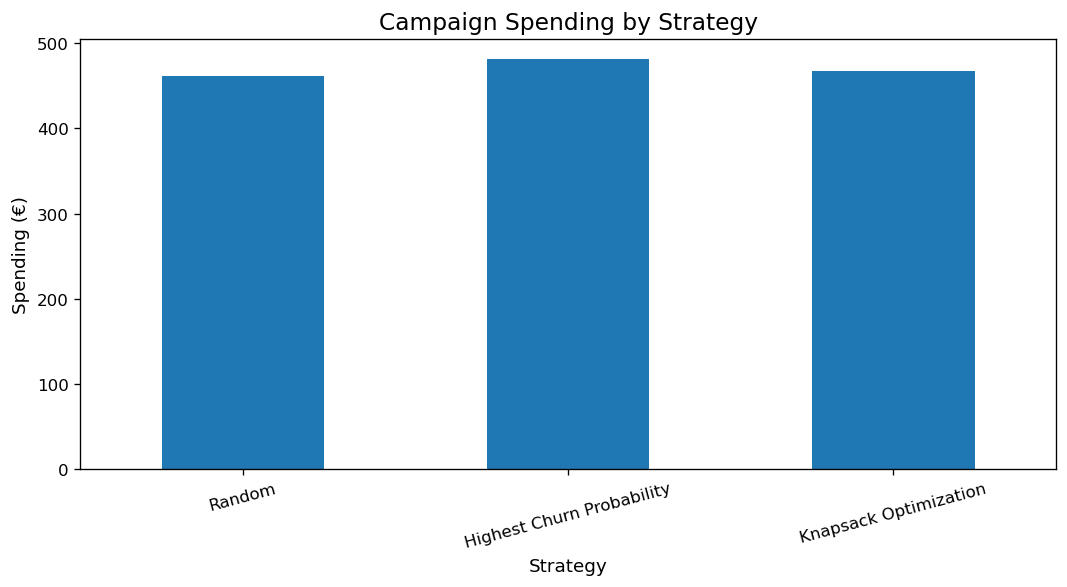

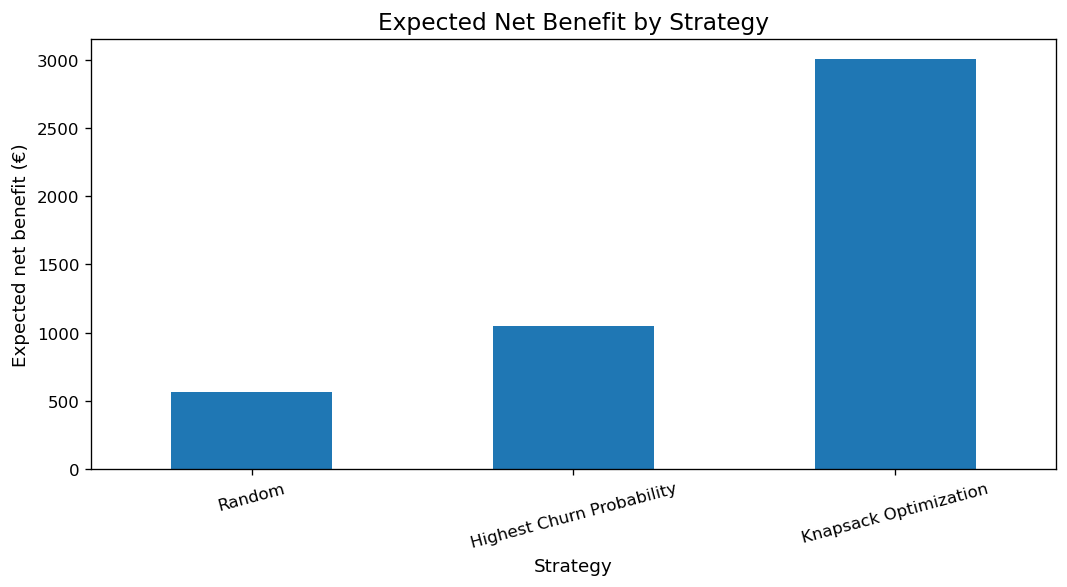

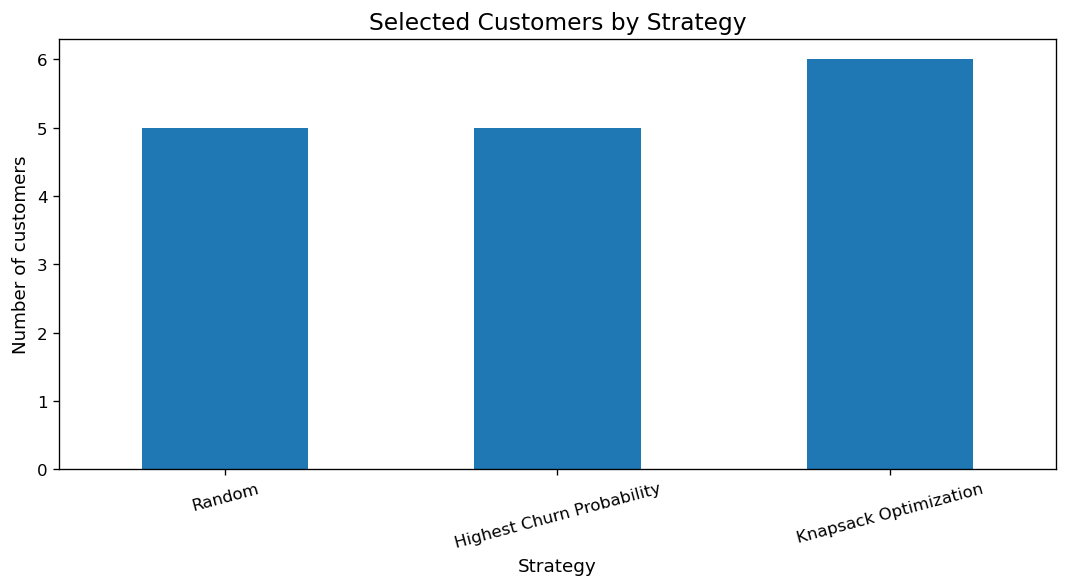

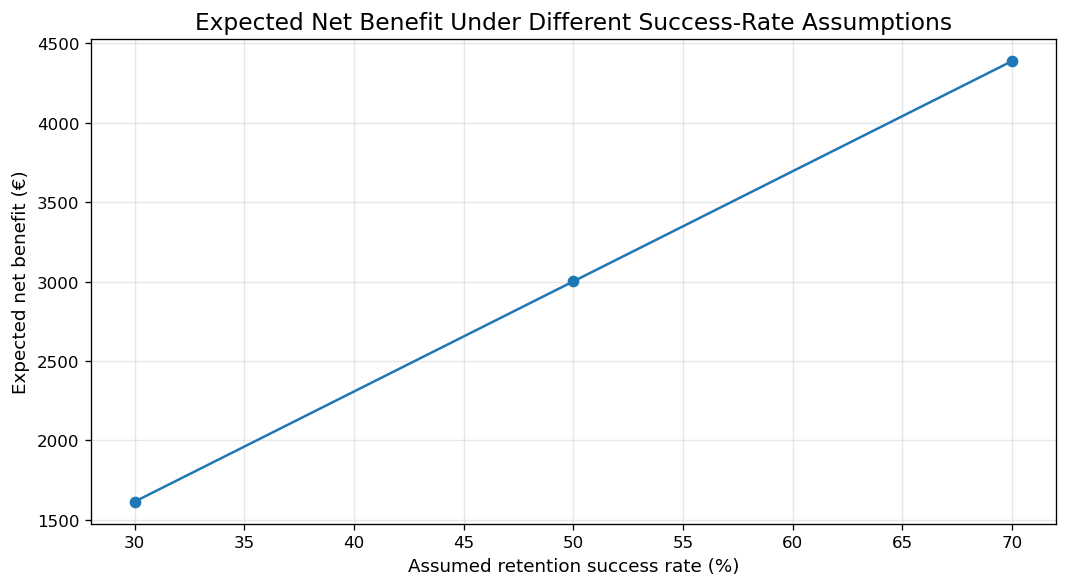

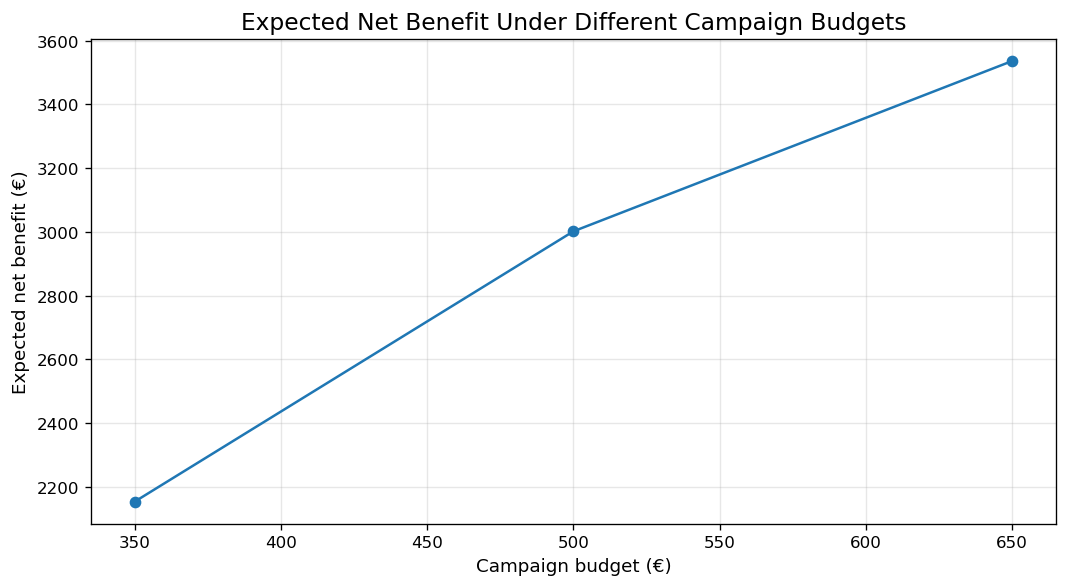

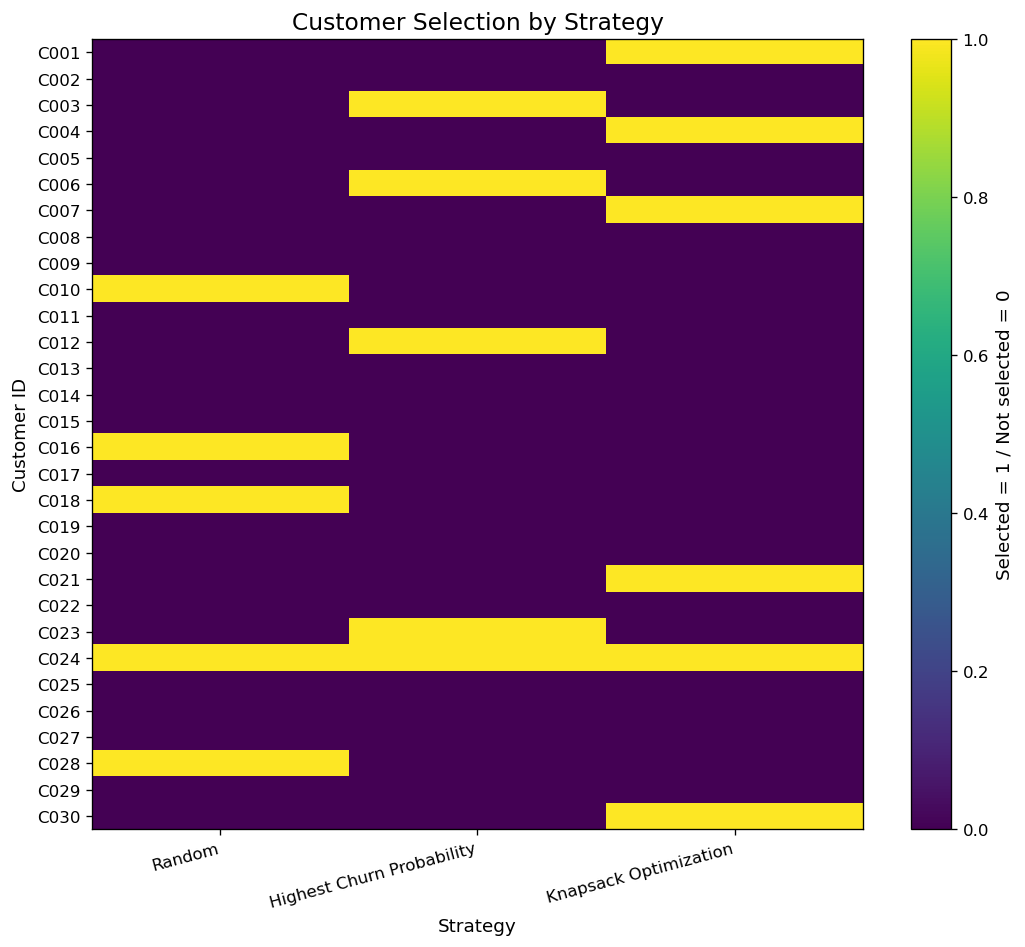

Charts generated and saved.


In [9]:
# Chart 1 — Campaign spending by strategy
fig, ax = plt.subplots()
comparison["Total Spending (€)"].plot(kind="bar", ax=ax)
ax.set_title("Campaign Spending by Strategy")
ax.set_xlabel("Strategy")
ax.set_ylabel("Spending (€)")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_campaign_spending_by_strategy.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# Chart 2 — Expected net benefit by strategy
fig, ax = plt.subplots()
comparison["Expected Net Benefit (€)"].plot(kind="bar", ax=ax)
ax.set_title("Expected Net Benefit by Strategy")
ax.set_xlabel("Strategy")
ax.set_ylabel("Expected net benefit (€)")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_expected_net_benefit_by_strategy.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# Chart 3 — Number of selected customers
fig, ax = plt.subplots()
comparison["Selected Customers"].plot(kind="bar", ax=ax)
ax.set_title("Selected Customers by Strategy")
ax.set_xlabel("Strategy")
ax.set_ylabel("Number of customers")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_selected_customers_by_strategy.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# Chart 4 — Sensitivity to success rate
fig, ax = plt.subplots()
ax.plot(
    success_sensitivity["Assumed Success Rate"] * 100,
    success_sensitivity["Expected Net Benefit (€)"],
    marker="o"
)
ax.set_title("Expected Net Benefit Under Different Success-Rate Assumptions")
ax.set_xlabel("Assumed retention success rate (%)")
ax.set_ylabel("Expected net benefit (€)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "05_sensitivity_to_success_rate.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# Chart 5 — Sensitivity to budget
fig, ax = plt.subplots()
ax.plot(
    budget_sensitivity["Budget (€)"],
    budget_sensitivity["Expected Net Benefit (€)"],
    marker="o"
)
ax.set_title("Expected Net Benefit Under Different Campaign Budgets")
ax.set_xlabel("Campaign budget (€)")
ax.set_ylabel("Expected net benefit (€)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "06_sensitivity_to_campaign_budget.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# Chart 6 — Customer selection matrix
selection_matrix = pd.DataFrame({
    strategy: df["Customer_ID"].isin(ids).astype(int).values
    for strategy, ids in strategies.items()
}, index=df["Customer_ID"])

fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(selection_matrix.values, aspect="auto", interpolation="nearest")
ax.set_title("Customer Selection by Strategy")
ax.set_xlabel("Strategy")
ax.set_ylabel("Customer ID")
ax.set_xticks(range(len(selection_matrix.columns)))
ax.set_xticklabels(selection_matrix.columns, rotation=15, ha="right")
ax.set_yticks(range(len(selection_matrix.index)))
ax.set_yticklabels(selection_matrix.index)
fig.colorbar(image, ax=ax, label="Selected = 1 / Not selected = 0")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "07_customer_selection_matrix.png", bbox_inches="tight")
plt.show()
plt.close(fig)

print("Charts generated and saved.")

# 15. Business recommendation: What should the decision-maker take away?

The recommendation must follow the evidence and remain within the limits of the data.

A defensible recommendation structure is:

1. **State the business constraint:** the campaign has a fixed budget.
2. **Explain why churn risk alone is insufficient:** it does not account for customer value or offer cost.
3. **Compare the strategies using expected net benefit:** this is the primary objective.
4. **Identify the optimized portfolio:** show which customers were selected and the total spend.
5. **Discuss sensitivity:** explain whether the result changes under the tested assumptions.
6. **State the limitations:** the records and probabilities are synthetic, and intervention success is hypothetical.

The Knapsack approach is the method most directly aligned with the stated objective because it optimizes total expected net benefit under the budget constraint. The numerical advantage observed in this exercise is illustrative, not proof of real-world campaign uplift.

# 16. Limitations and what would be needed in a real business deployment

A professional analyst should explain not only what the analysis shows, but also what it cannot show.

### Limitations of this project

- **Synthetic records:** the 30 customers are fictional, so the results are not representative of a real customer base.
- **Simulated churn probabilities:** no predictive model is trained or validated in this notebook.
- **Estimated CLV:** the project treats the supplied CLV values as inputs; their estimation method is outside the scope of this exercise.
- **Hypothetical success rate:** the 50% base rate is a scenario assumption, not an experimentally measured retention effect.
- **Simplified economics:** the formula treats CLV as the value preserved and does not explicitly model margins, discounting, timing, partial retention, or offer-specific effects.
- **No causal evaluation:** the analysis cannot establish that an offer caused a customer to stay.
- **Small dataset:** 30 records are sufficient to demonstrate the method, but not to support a production business decision.

### What a real company should add

- real, governed customer and transaction data;
- a trained and validated churn model with calibration checks;
- a defensible CLV calculation based on contribution margin and expected customer lifetime;
- experimental estimates of retention-offer effectiveness, ideally from randomized tests;
- operational constraints such as eligibility, contact limits, channel capacity, and customer experience;
- monitoring after deployment to compare predicted and realized outcomes.

# 17. Extensions: verification, a smarter heuristic, and risk

The analysis above answers the core question. This section uses the project's `odin` package (in `src/odin/`) to go further and to check the result independently:

1. **Verify optimality.** An exhaustive search over every subset of positive-benefit customers should find the same total as the dynamic-programming solver.
2. **Try a stronger baseline.** The *value-density* greedy rule ranks customers by expected net benefit per euro spent. It is the textbook knapsack heuristic, so it is a much tougher comparison than "highest churn first".
3. **Quantify risk.** Expected values hide variance. A Monte Carlo simulation replays the campaign many times: each customer either churns or not, and each offer either works or not. This gives a distribution of *realised* net benefit and a probability of losing money.
4. **Map the assumptions.** A full budget × success-rate grid shows where the strategy is robust and where it depends on the assumptions.


In [10]:
import sys
sys.path.insert(0, str(ROOT / "src"))

from odin import add_expected_value, brute_force_selection, knapsack_selection
from odin.evaluation import compare_strategies, optimality_gap, run_strategies
from odin.sensitivity import sensitivity_grid
from odin.simulation import simulate_net_benefit, summarise_simulations

pkg_df = add_expected_value(df[EXPECTED_COLUMNS], BASE_SUCCESS_RATE)

# 1) Exhaustive search confirms the DP solution
dp_ids = knapsack_selection(pkg_df, CAMPAIGN_BUDGET)
eligible = pkg_df[pkg_df["Expected_Net_Benefit"] > 0]
print(f"Positive-benefit candidates: {len(eligible)} -> {2 ** len(eligible):,} subsets")

# Brute force over the 20 highest-benefit candidates (2^20 ≈ 1M subsets) to keep runtime short;
# tests/test_strategies.py checks DP == brute force on many random instances as well.
top = eligible.nlargest(20, "Expected_Net_Benefit")
bf_ids = brute_force_selection(top, CAMPAIGN_BUDGET, max_items=20)
dp_top = knapsack_selection(top, CAMPAIGN_BUDGET)
print("DP  (top-20):", dp_top)
print("Brute force :", bf_ids)
assert sorted(dp_top) == sorted(bf_ids)
assert sorted(dp_ids) == sorted(strategies["Knapsack Optimization"])
print("Optimality verified on the top-20 candidates: dynamic programming == exhaustive search.")

# 2) Four-strategy comparison, including the value-density heuristic
selections = run_strategies(pkg_df, CAMPAIGN_BUDGET, seed=RANDOM_SEED)
extended = compare_strategies(pkg_df, selections)
extended["Share of Optimum"] = optimality_gap(extended)
display(extended.round(2))


Positive-benefit candidates: 25 -> 33,554,432 subsets
DP  (top-20): ['C001', 'C004', 'C007', 'C021', 'C024', 'C030']
Brute force : ['C001', 'C004', 'C007', 'C021', 'C024', 'C030']
Optimality verified on the top-20 candidates: dynamic programming == exhaustive search.


,Selected Customers,Total Spending (€),Expected Retained Value (€),Expected Net Benefit (€),ROI,Actual Churners Captured,Actual Churn Capture Rate,Share of Optimum
Strategy,,,,,,,,
Random,5.0,462.0,1028.32,566.32,1.23,1.0,0.07,0.19
Highest Churn Probability,5.0,481.0,1528.68,1047.68,2.18,5.0,0.33,0.35
Value Density (Greedy),6.0,467.0,3468.39,3001.39,6.43,5.0,0.33,1.00
Knapsack Optimization,6.0,467.0,3468.39,3001.39,6.43,5.0,0.33,1.00


**Reading the extended comparison.** On this small dataset the value-density heuristic happens to find the same portfolio as the knapsack solver. That is not guaranteed. On the 1,000-customer synthetic dataset in `data/synthetic/` (see the README), the greedy rule leaves money on the table, while the knapsack solver stays exactly optimal and still runs in well under a second.


,Mean Net Benefit (€),Std Dev (€),5th Percentile (€),Median (€),95th Percentile (€),Probability of Loss
Strategy,,,,,,
Random,568.553,915.432,-462.0,447.0,1963.0,0.336
Highest Churn Probability,1061.361,928.021,-481.0,1035.0,2553.0,0.161
Value Density (Greedy),3005.003,1917.698,-467.0,2794.0,6133.0,0.073
Knapsack Optimization,3005.003,1917.698,-467.0,2794.0,6133.0,0.073


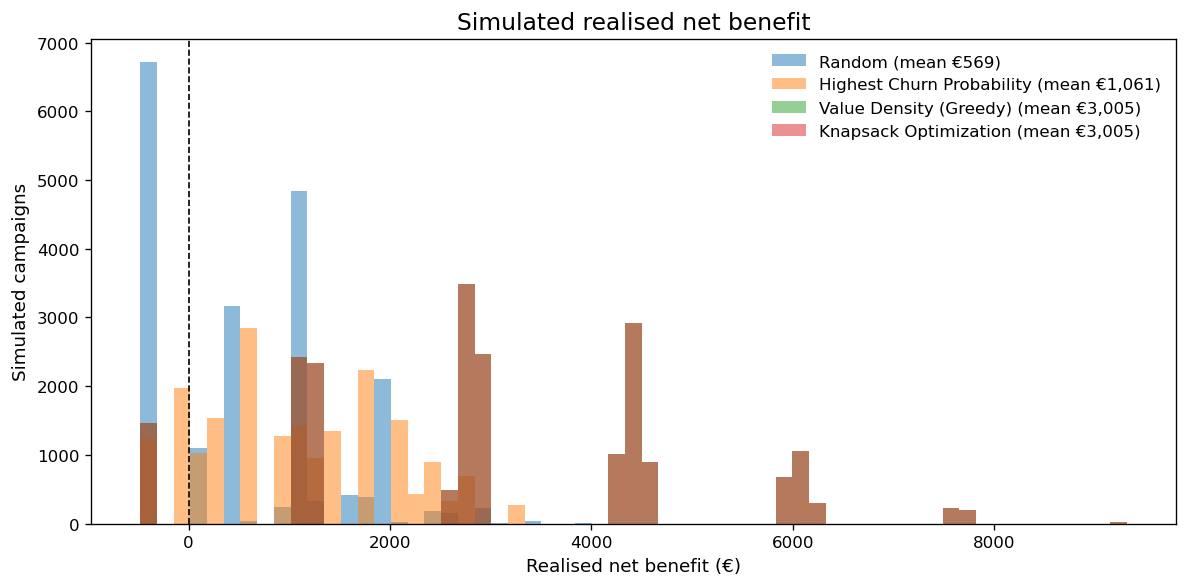

In [11]:
# 3) Monte Carlo risk of each strategy's portfolio
simulations = {
    name: simulate_net_benefit(pkg_df, ids, BASE_SUCCESS_RATE, runs=20_000, seed=RANDOM_SEED)
    for name, ids in selections.items()
}
risk = summarise_simulations(simulations)
display(risk.round(3))

fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(min(s.min() for s in simulations.values()), max(s.max() for s in simulations.values()), 60)
for name, sims in simulations.items():
    ax.hist(sims, bins=bins, alpha=0.5, label=f"{name} (mean €{sims.mean():,.0f})")
ax.axvline(0, color="black", ls="--", lw=1)
ax.set_title("Simulated realised net benefit")
ax.set_xlabel("Realised net benefit (€)")
ax.set_ylabel("Simulated campaigns")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_monte_carlo_net_benefit.png", bbox_inches="tight")
plt.show()
plt.close(fig)


**Reading the risk table.** The mean of the simulations converges to the expected net benefit computed analytically, which is a useful sanity check. The new information is the spread. The optimised portfolio has the highest mean and the lowest probability of ending in a loss. Its absolute spread (standard deviation) is larger, because it concentrates the budget on high-CLV customers. Its worst case is still bounded by the campaign spend, though: the 5th percentile equals losing the full offer cost, the same as for every other strategy.


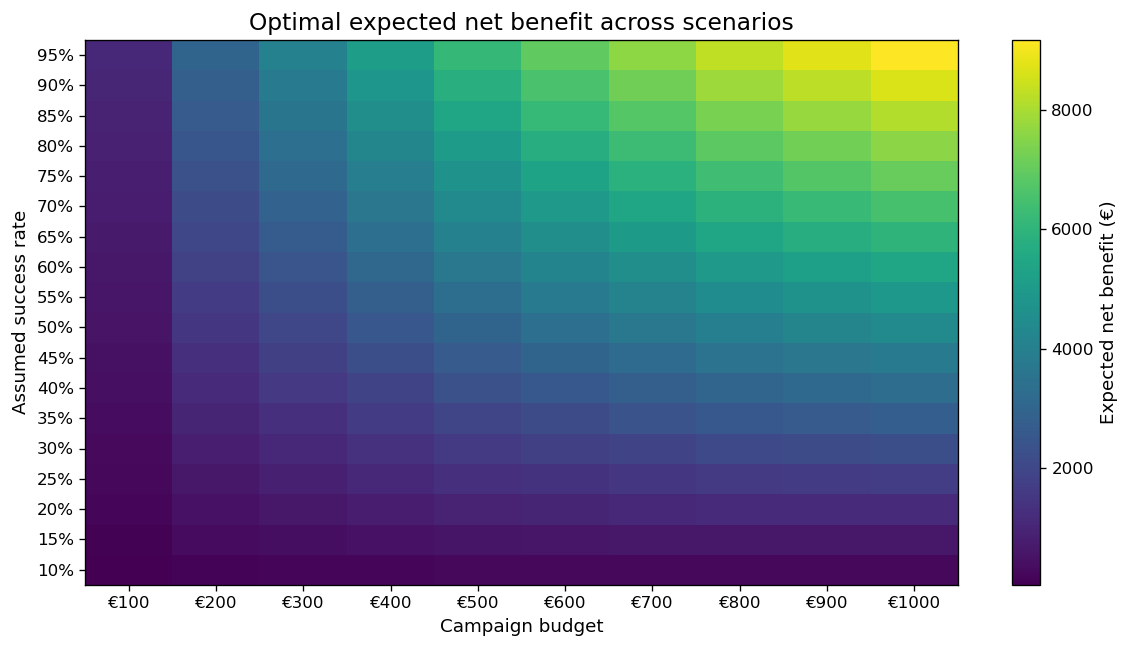

In [12]:
# 4) Two-way sensitivity grid
rates = np.round(np.arange(0.10, 0.951, 0.05), 2)
budgets = list(range(100, 1001, 100))
grid = sensitivity_grid(df[EXPECTED_COLUMNS], rates, budgets)

fig, ax = plt.subplots(figsize=(10, 5.5))
image = ax.imshow(grid.values, aspect="auto", origin="lower", cmap="viridis")
ax.set_xticks(range(len(budgets)), [f"€{b}" for b in budgets])
ax.set_yticks(range(len(rates)), [f"{r:.0%}" for r in rates])
ax.set_xlabel("Campaign budget")
ax.set_ylabel("Assumed success rate")
ax.set_title("Optimal expected net benefit across scenarios")
fig.colorbar(image, ax=ax, label="Expected net benefit (€)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "09_sensitivity_heatmap.png", bbox_inches="tight")
plt.show()
plt.close(fig)

grid.to_csv(TABLE_DIR / "sensitivity_grid.csv")
risk.to_csv(TABLE_DIR / "monte_carlo_risk.csv")


**Reading the heatmap.** Benefit rises with both budget and success rate, but the budget effect flattens out: once the high-value customers have been funded, each extra euro buys less. A decision-maker can use this map to see how much a bigger budget is worth under each belief about how well the offer works.


# 18. Final conclusion

Project Odin demonstrates how a business can move from identifying churn risk to making a financially informed retention decision under a limited budget.

The key insight is that **the customer most likely to churn is not automatically the customer who should receive the offer**. A stronger decision considers churn probability together with customer economic value and intervention cost.

The analysis calculates expected retained value and expected net benefit for each customer, compares simple selection baselines, and applies 0/1 Knapsack optimization to identify the combination with the highest modeled total net benefit under the budget.

The conclusion is conditional on a synthetic dataset and hypothetical assumptions. The project demonstrates a decision framework; it does not claim measured real-world retention impact.

---

## Reproducibility and exported deliverables

The analysis tables are saved in `outputs/notebook/tables/`, and charts are saved in `outputs/notebook/figures/`. The original input CSV remains unchanged.

In [13]:
# Export all analysis tables
customer_economics.to_csv(
    TABLE_DIR / "customer_economic_analysis.csv", index=False
)
df.to_csv(
    TABLE_DIR / "customer_analysis_full.csv", index=False
)
comparison.to_csv(
    TABLE_DIR / "strategy_comparison.csv"
)
selected_portfolio.to_csv(
    TABLE_DIR / "knapsack_selected_customers.csv", index=False
)
success_sensitivity.to_csv(
    TABLE_DIR / "sensitivity_success_rate.csv", index=False
)
budget_sensitivity.to_csv(
    TABLE_DIR / "sensitivity_budget.csv", index=False
)

print("Exported tables:")
for file in sorted(TABLE_DIR.glob("*.csv")):
    print(" -", file)

print("\nSaved charts:")
for file in sorted(FIGURE_DIR.glob("*.png")):
    print(" -", file)

Exported tables:
 - /Users/afrooz/Downloads/Project_Odin_Professional/outputs/notebook/tables/customer_analysis_full.csv
 - /Users/afrooz/Downloads/Project_Odin_Professional/outputs/notebook/tables/customer_economic_analysis.csv
 - /Users/afrooz/Downloads/Project_Odin_Professional/outputs/notebook/tables/knapsack_selected_customers.csv
 - /Users/afrooz/Downloads/Project_Odin_Professional/outputs/notebook/tables/monte_carlo_risk.csv
 - /Users/afrooz/Downloads/Project_Odin_Professional/outputs/notebook/tables/sensitivity_budget.csv
 - /Users/afrooz/Downloads/Project_Odin_Professional/outputs/notebook/tables/sensitivity_grid.csv
 - /Users/afrooz/Downloads/Project_Odin_Professional/outputs/notebook/tables/sensitivity_success_rate.csv
 - /Users/afrooz/Downloads/Project_Odin_Professional/outputs/notebook/tables/strategy_comparison.csv

Saved charts:
 - /Users/afrooz/Downloads/Project_Odin_Professional/outputs/notebook/figures/01_customer_dataset_overview.png
 - /Users/afrooz/Downloads/Projec